K-Means Accuracy: 76.0 %
DBSCAN Accuracy: 50.26 %


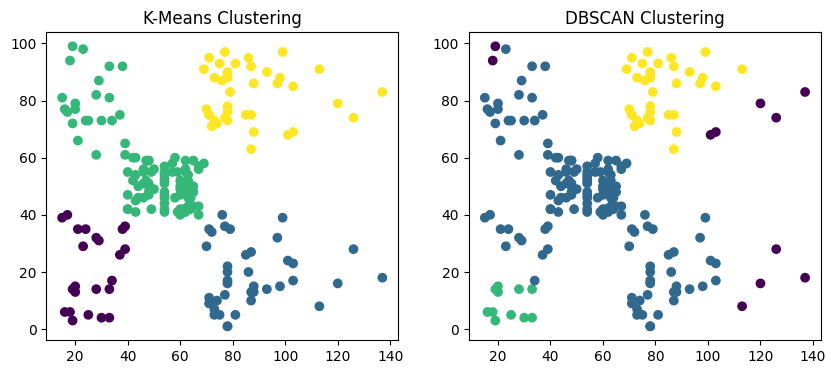

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Load dataset
data = pd.read_csv("Mall_Customers.csv")

# Select features
X = data[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Scale data
X = StandardScaler().fit_transform(X)

# Create reference groups
income = data['Annual Income (k$)']
spending = data['Spending Score (1-100)']

true = np.where(income < income.median(),
                np.where(spending < spending.median(), 0, 1),
                np.where(spending < spending.median(), 2, 3))

# Apply K-Means
km = KMeans(n_clusters=4, random_state=42, n_init=10)
k_labels = km.fit_predict(X)

# Apply DBSCAN
db = DBSCAN(eps=0.45, min_samples=5)
d_labels = db.fit_predict(X)

# Calculate accuracy
def accuracy(true, labels):
    valid = labels != -1
    true, labels = true[valid], labels[valid]
    correct = 0

    for c in np.unique(labels):
        mask = labels == c
        groups, counts = np.unique(true[mask], return_counts=True)
        correct += counts.max()

    return correct / len(true) * 100 if len(true) else 0

a1 = accuracy(true, k_labels)
a2 = accuracy(true, d_labels)

print("K-Means Accuracy:", round(a1, 2), "%")
print("DBSCAN Accuracy:", round(a2, 2), "%")

# Plot graphs
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(data['Annual Income (k$)'],
            data['Spending Score (1-100)'], c=k_labels)
plt.title("K-Means Clustering")

plt.subplot(1, 2, 2)
plt.scatter(data['Annual Income (k$)'],
            data['Spending Score (1-100)'], c=d_labels)
plt.title("DBSCAN Clustering")

plt.show()
